# Análisis de resultados del scraping

Cafeteras de hogar e insumos de café en Mercado Libre Colombia.
Este notebook se ejecuta en cada despliegue con los datos generados por el pipeline.
Código y documentación: https://github.com/duvandeguerra/web-scrapping

## 1. Carga de datos

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from scraping.parsers import leer_listados

bs = pd.DataFrame(leer_listados("html"))
sc = pd.read_csv("datos/datos_scrapy.csv")
with open("datos/fichas_selenium.json", encoding="utf-8") as f:
    fichas = pd.DataFrame(json.load(f))

print(f"BeautifulSoup: {len(bs)} | Scrapy: {len(sc)} | Fichas Selenium: {len(fichas)}")

BeautifulSoup: 456 | Scrapy: 456 | Fichas Selenium: 25


## 2. BeautifulSoup frente a Scrapy

In [2]:
pd.DataFrame({
    "BeautifulSoup": bs.groupby("tipo").size(),
    "Scrapy": sc.groupby("tipo").size(),
})

,BeautifulSoup,Scrapy
tipo,,
insumo_capsulas,112,112
insumo_grano,108,108
maquina_capsulas,120,120
maquina_grano_molido,116,116


## 3. Métricas de calidad

In [3]:
pd.Series({
    "Registros": len(bs),
    "Únicos por URL": bs["url"].nunique(),
    "Duplicados (%)": round((1 - bs["url"].nunique() / len(bs)) * 100, 1),
    "Precio completo (%)": round(bs["precio"].notna().mean() * 100, 1),
    "Envío gratis (%)": round(bs["envio_gratis"].mean() * 100, 1),
})

Registros              456.0
Únicos por URL         332.0
Duplicados (%)          27.2
Precio completo (%)    100.0
Envío gratis (%)        69.3
dtype: float64

## 4. Precios por categoría

In [4]:
resumen = bs.groupby("tipo").agg(
    registros=("titulo", "count"),
    mediana=("precio", "median"),
    minimo=("precio", "min"),
    maximo=("precio", "max"),
    envio_gratis_pct=("envio_gratis", lambda s: round(s.mean() * 100, 1)),
)
resumen

,registros,mediana,minimo,maximo,envio_gratis_pct
tipo,,,,,
insumo_capsulas,112,87180.0,6000,672000,56.2
insumo_grano,108,47000.0,18750,346000,45.4
maquina_capsulas,120,496386.0,15171,3418297,79.2
maquina_grano_molido,116,464900.0,8692,22000000,94.0


## 5. Gráficos

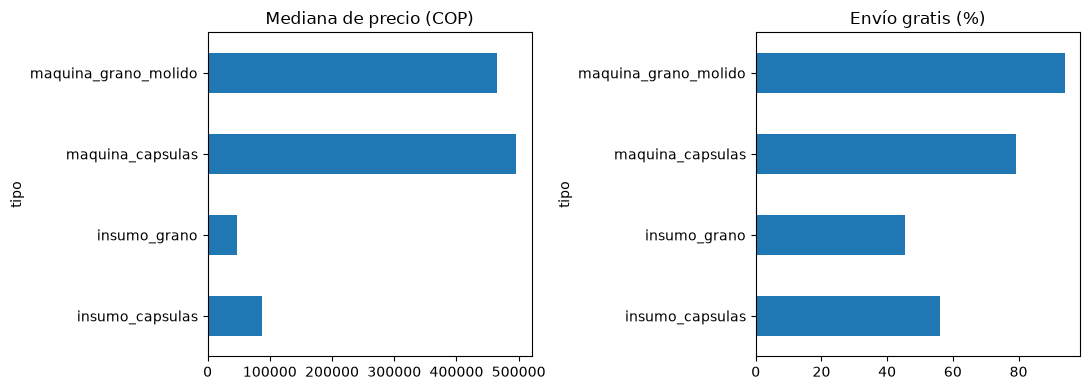

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
resumen["mediana"].plot.barh(ax=ax[0], title="Mediana de precio (COP)")
resumen["envio_gratis_pct"].plot.barh(ax=ax[1], title="Envío gratis (%)")
plt.tight_layout()
plt.show()

## 6. Fichas de producto

In [6]:
fichas["n_specs"] = fichas["especificaciones"].apply(len)
fichas["tiene_resumen_ia"] = fichas["resumen_ia"].notna()
fichas[["producto", "precio", "calificacion", "num_opiniones", "n_specs", "tiene_resumen_ia"]]

,producto,precio,calificacion,num_opiniones,n_specs,tiene_resumen_ia
0,Krups Coffee Crush Extra,1.299.900,5.0,(4),12,False
1,Nespresso Essenza Mini,468.999,4.9,(304),27,True
2,Nespresso Vertuo Pop,836.500,5.0,(2),7,False
3,KRUPS Espresso Essential,1.999.900,4.6,(65),22,True
4,Cafetera Espresso Capuccino,254.925,4.8,(36),13,False
5,Cafetera Espresso Portátil,137.081,NaN,NaN,12,False
6,Cafetera Automática Espresso,595.335,4.6,(132),37,True
7,Cafetera Espresso Compacta,1.299.900,4.5,(25),32,True
8,Cafetera Espresso Perfect Brew,844.935,4.9,(17),36,True
9,Cafetera Espresso Kalley,283.900,4.7,(358),17,True
